# Task 3: Predictive Customer Churn Classifier

## 1. Project Overview

The objective of this project is to predict customer churn
using telecommunications subscription data.

We will train and compare two classification models:
- Random Forest Classifier
- XGBoost Classifier

## Project Objectives

1. Load and inspect the Telco Customer Churn dataset.
2. Clean the data and convert TotalCharges to numeric.
3. Explore customer churn patterns and class imbalance.
4. Split the data into training and testing sets.
5. Encode categorical features and preprocess numerical data.
6. Handle class imbalance using appropriate class weighting.
7. Train and evaluate Random Forest and XGBoost.
8. Perform cross-validation and compare model performance.
9. Evaluate ROC-AUC, recall, precision, and F1-score.
10. Plot ROC curves and a confusion matrix.
11. Visualize the top 10 most influential features.

## Expected Outcome

A documented Jupyter Notebook containing the data analysis,
preprocessing, trained classifiers, evaluation metrics,
ROC curve, confusion matrix, and feature importance chart.

## 2. Import Required Libraries

We use Pandas and NumPy for data manipulation, Matplotlib
and Seaborn for visualization, and Scikit-learn for
preprocessing, model training, and evaluation.

Additional libraries for XGBoost and class imbalance
handling will be imported where needed.

In [1]:
# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load the Telco Customer Churn Dataset

We will load the Telco Customer Churn dataset directly from
its public CSV URL using Pandas.

The dataset contains customer demographics, subscription
services, billing information, and the target variable
`Churn`.

Our goal is to predict whether a customer will leave the
telecommunications service.

At this stage, we will load and inspect the data before
performing any cleaning or preprocessing.

In [2]:
# URL of the Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load the CSV file into a Pandas DataFrame
df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 4. Initial Dataset Inspection

Before cleaning the dataset, we need to understand its
structure and data quality.

We will:
- Check the number of rows and columns.
- Preview the first five records.
- Inspect column names and data types.
- Count missing values in each column.

This inspection will help us identify data-cleaning
requirements, especially for `TotalCharges`.


In [3]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Preview the first five records
display(df.head())

# Inspect column names, data types, and non-null counts
df.info()

# Count missing values in each column
print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 5. Clean and Convert TotalCharges

The `TotalCharges` column is stored as an object instead
of a numeric data type.

Some records may contain blank strings or whitespace.
We will remove surrounding whitespace and convert the
column to numeric values.

Invalid or blank values will be converted to NaN so they
can be handled correctly during preprocessing.

We will inspect the resulting missing values before
deciding how to handle them.

In [4]:
# Convert TotalCharges to numeric and detect blank values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Verify the converted data type
print("TotalCharges data type:", df["TotalCharges"].dtype)

# Check missing values in the dataset
print("\nMissing values per column:")
display(
    df.isnull().sum()
    .to_frame(name="Missing Values")
    .sort_values("Missing Values", ascending=False)
)

# Display the total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())

TotalCharges data type: float64

Missing values per column:


,Missing Values
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0



Total missing values: 11


## 6. Exploratory Data Analysis: Customer Churn

The target variable is `Churn`, which indicates whether a
customer left the telecommunications service.

We will examine the number and percentage of customers
in each churn category.

This analysis helps us identify class imbalance before
splitting the data and training classification models.

,Customer Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


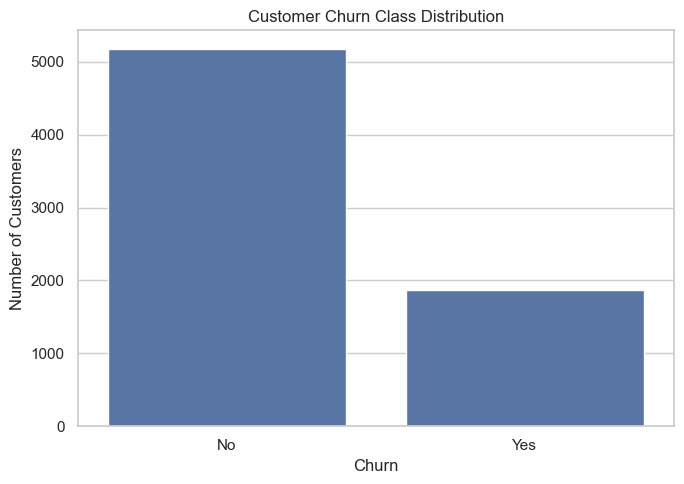

In [5]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Calculate the percentage of each category
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

# Display counts and percentages
churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage (%)": churn_percentages.round(2)
})

display(churn_summary)

# Visualize the class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 7. Split the Dataset into Training and Testing Sets

We separate the input features from the target variable `Churn`.

The `customerID` column is removed because it is an identifier
rather than a meaningful customer behaviour feature.

We split the dataset into 80% training data and 20% testing data.
Stratified splitting preserves approximately the same churn
class proportions in both sets.

The test set will remain separate for final model evaluation.
Missing-value imputation, encoding, and class balancing will
be handled after the split to prevent data leakage.

In [6]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# Check class distribution in both sets
print("\nTraining target distribution:")
display(y_train.value_counts().to_frame(name="Count"))

print("\nTesting target distribution:")
display(y_test.value_counts().to_frame(name="Count"))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:


,Count
Churn,
No,4139
Yes,1495



Testing target distribution:


,Count
Churn,
No,1035
Yes,374


## 8. Data Preprocessing

Machine-learning models require the input data to be
processed consistently.

In this section, we will:
- Impute missing numerical values using the median.
- Impute missing categorical values using the most frequent value.
- Encode categorical features using OneHotEncoder.

We will fit the preprocessing steps on training data only.
The preprocessing will be included inside each model pipeline
to prevent data leakage during cross-validation.

Since Random Forest and XGBoost are tree-based models,
numerical feature scaling is not required for this task.


In [7]:
# Import preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Pipeline for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline configured successfully.")

print(
    "\nMissing TotalCharges in training data:",
    X_train["TotalCharges"].isnull().sum()
)

print(
    "Missing TotalCharges in testing data:",
    X_test["TotalCharges"].isnull().sum()
)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline configured successfully.

Missing TotalCharges in training data: 8
Missing TotalCharges in testing data: 3


## 9. Class Imbalance and Model Training

The churn dataset is imbalanced: approximately 73% of customers
belong to the "No" class and 27% to the "Yes" class.

We will address this using class weighting:
- Random Forest will use `class_weight="balanced"`.
- XGBoost will use `scale_pos_weight` based on the training
  class distribution.

We will compare both models using stratified five-fold
cross-validation and ROC-AUC, precision, recall, and F1-score.

All preprocessing will remain inside each model pipeline
to prevent data leakage during cross-validation.

In [8]:
# Import models and cross-validation tools
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline

# Encode churn labels for binary classification
# No = 0, Yes = 1
y_train_encoded = y_train.map({"No": 0, "Yes": 1})
y_test_encoded = y_test.map({"No": 0, "Yes": 1})

print("Encoded training labels:")
print(y_train_encoded.value_counts())

# Calculate class imbalance ratio using training data only
negative_count = (y_train_encoded == 0).sum()
positive_count = (y_train_encoded == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\nNegative class count:", negative_count)
print("Positive class count:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))

# Build the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Build the XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Stratified five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate churn as the positive class (label 1)
scoring = {
    "roc_auc": "roc_auc",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    )
}

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train_encoded,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": model_name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

    # Fit the model on the complete training set
    model.fit(X_train, y_train_encoded)

# Compare cross-validation results
cv_results_df = pd.DataFrame(cv_results).sort_values(
    "ROC-AUC",
    ascending=False
)

display(cv_results_df.round(4))

print("\nBoth models completed cross-validation and training.")

Encoded training labels:
Churn
0    4139
1    1495
Name: count, dtype: int64

Negative class count: 4139
Positive class count: 1495
XGBoost scale_pos_weight: 2.769


,Model,ROC-AUC,Precision,Recall,F1-Score
1,XGBoost,0.8446,0.5356,0.7746,0.6332
0,Random Forest,0.8212,0.6309,0.4722,0.5399



Both models completed cross-validation and training.


## 10. Test Set Evaluation: ROC-AUC and Confusion Matrix

We evaluate the trained Random Forest and XGBoost models on
the held-out test set.

We will calculate:
- ROC-AUC
- Precision, recall, and F1-score
- Confusion matrices

We will also plot ROC curves to compare how well each model
distinguishes customers who churn from those who do not churn.

The positive class is `Yes` (encoded as 1). The test set will
not be used for fitting or tuning the models.


Random Forest — Classification Report
              precision    recall  f1-score   support

    No Churn       0.82      0.90      0.86      1035
       Churn       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409


XGBoost — Classification Report
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409


Test Set Model Comparison:


,Model,ROC-AUC,Precision,Recall,F1-Score
1,XGBoost,0.8405,0.5291,0.7781,0.6299
0,Random Forest,0.8224,0.6170,0.4652,0.5305


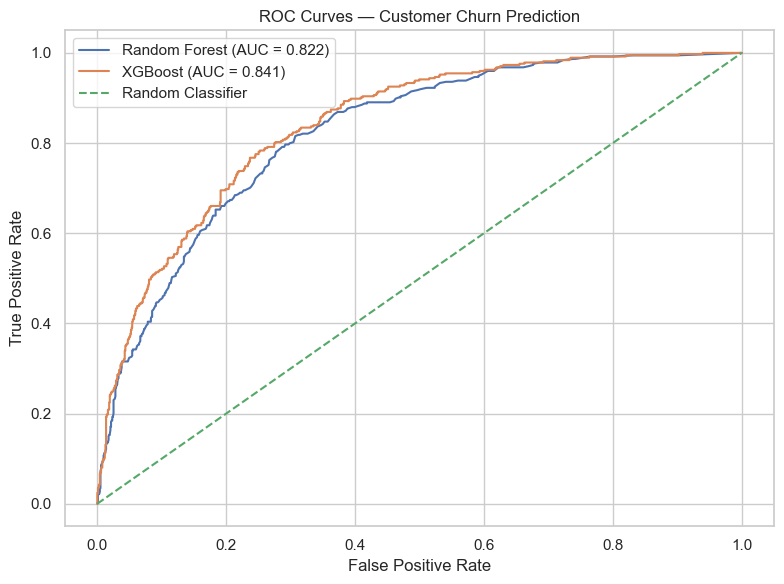

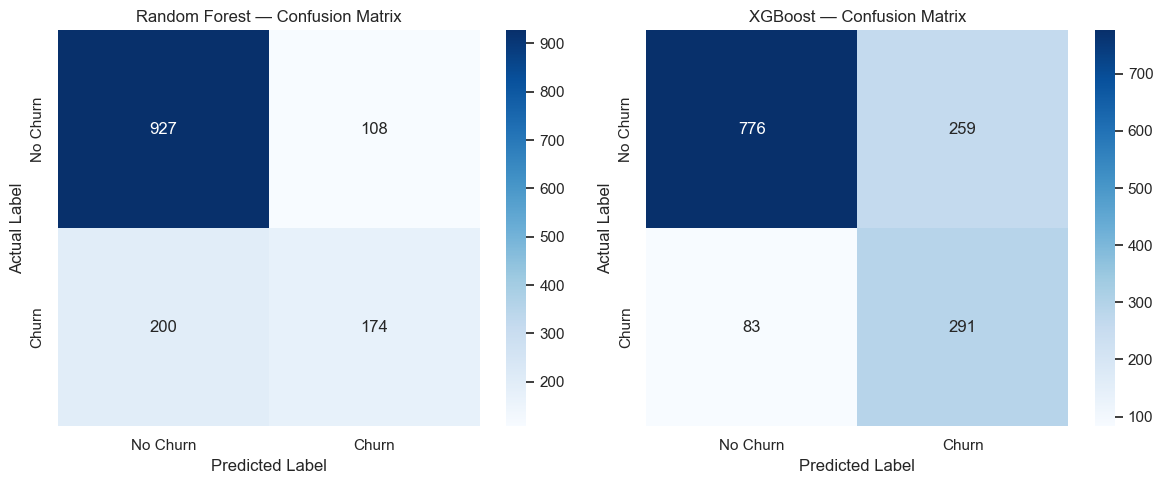

In [9]:
# Import evaluation tools
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Store test predictions and evaluation results
test_predictions = {}
test_probabilities = {}
test_results = []

for model_name, model in models.items():

    # Predict churn labels and probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = y_pred
    test_probabilities[model_name] = y_prob

    # Calculate test-set metrics
    test_results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_test_encoded, y_prob),
        "Precision": precision_score(
            y_test_encoded, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_encoded, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_encoded, y_pred, zero_division=0
        )
    })

    print(f"\n{model_name} — Classification Report")
    print(classification_report(
        y_test_encoded,
        y_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

# Display the test-set comparison
test_results_df = pd.DataFrame(test_results).sort_values(
    "ROC-AUC", ascending=False
)

print("\nTest Set Model Comparison:")
display(test_results_df.round(4))

# Plot ROC curves for both models
plt.figure(figsize=(8, 6))

for model_name, y_prob in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test_encoded, y_prob)
    auc_score = roc_auc_score(y_test_encoded, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# Reference line for random guessing
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves — Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

# Plot confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test_encoded,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

## 11. Feature Importance Analysis

We will examine the feature importance values of the trained
XGBoost classifier to identify the top 10 features.

The preprocessing pipeline transforms categorical features
into encoded columns. We will retrieve the transformed feature
names so that the importance values match the correct features.

A horizontal bar chart will display the most influential
features according to the trained model.

Feature importance indicates how the model uses features;
it does not establish causation.

,Feature,Importance
0,cat__Contract_Month-to-month,0.3595
1,cat__InternetService_Fiber optic,0.1024
2,cat__OnlineSecurity_No,0.0701
3,cat__TechSupport_No,0.0538
4,cat__Contract_Two year,0.0439
5,cat__StreamingMovies_Yes,0.0239
6,cat__InternetService_DSL,0.0219
7,cat__OnlineSecurity_No internet service,0.0204
8,cat__Contract_One year,0.0201
9,cat__PaymentMethod_Electronic check,0.0198


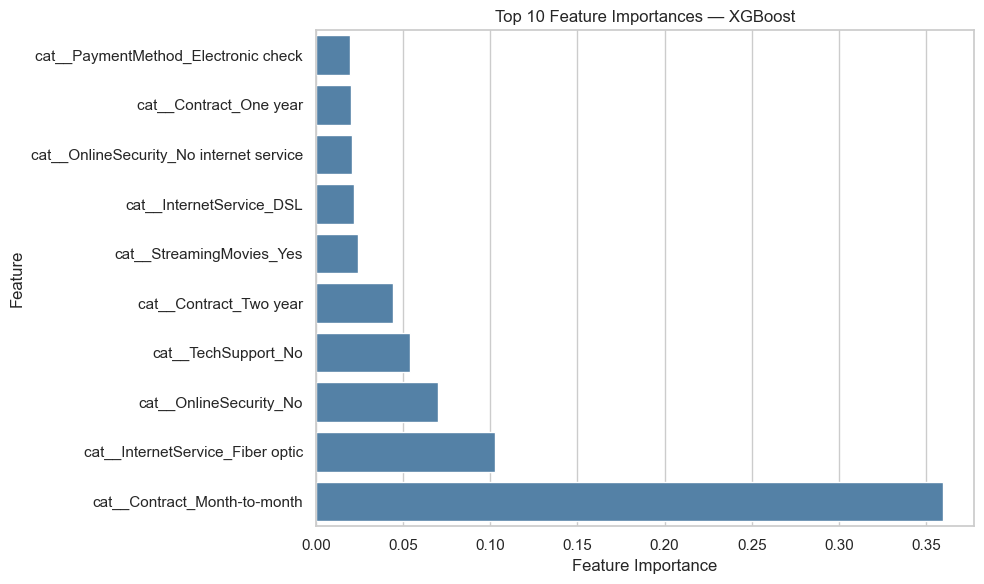

In [10]:
# Select the trained XGBoost pipeline
best_model = models["XGBoost"]

# Retrieve the fitted preprocessor and classifier
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

# Get feature names after preprocessing and encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance values
importance_values = fitted_classifier.feature_importances_

# Create a table of feature importance
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Select the top 10 most important features
top_10_features = (
    feature_importance_df
    .nlargest(10, "Importance")
    .sort_values("Importance", ascending=True)
)

# Display the top 10 features
display(
    top_10_features.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True).round(4)
)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Feature Importances — XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 12. Conclusion

This project developed and evaluated customer churn
classification models using the Telco Customer Churn dataset.

The dataset was cleaned by converting `TotalCharges` to
numeric values, and the target class distribution was
examined. The data was split into training and testing
sets using stratification.

A preprocessing pipeline was configured to impute missing
values and encode categorical features. Class imbalance
was addressed using class weighting for Random Forest
and `scale_pos_weight` for XGBoost.

Both models were evaluated using five-fold cross-validation
and a held-out test set.

XGBoost achieved a test ROC-AUC of approximately 0.8405,
compared with 0.8224 for Random Forest. XGBoost also
achieved higher recall (0.7781) and F1-score (0.6299),
making it the preferred model for identifying potential
churners in this experiment.

Feature importance analysis identified month-to-month
contracts as the most influential feature in the trained
XGBoost model, followed by fiber-optic internet service
and the absence of online security.

The project demonstrates data cleaning, class imbalance
handling, model evaluation, ROC-AUC analysis, confusion
matrices, and feature importance visualization.